In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
model_results_files = {
    "h-optimus-1": [
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_h-optimus-1_2010_1056_pathocell2_3726201/train/test_results/test_metrics_best_model.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_h-optimus-1_2110_2323_pathocell2_3752807/train/test_results/test_metrics_best_model.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_h-optimus-1_2110_2323_pathocell2_3752808/train/test_results/test_metrics_best_model.csv",
    ],
    "uni2": [
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_uni2_1610_1101_pathocell2_3658092/train/test_results/test_metrics_best_model.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_uni2_1710_1327_pathocell2_3679630/train/test_results/test_metrics_best_model.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_uni2_2110_1649_pathocell2_3749452/train/test_results/test_metrics_best_model.csv",
    ],
    "virchow2": [
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_virchow2_1910_1729_pathocell2_3720066/train/test_results/test_metrics_best_model.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_virchow2_2010_1051_pathocell2_3726138/train/test_results/test_metrics_best_model.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_virchow2_2110_1649_pathocell2_3749456/train/test_results/test_metrics_best_model.csv",
    ],
    "hovernext": [
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/hovernext_lizard_clweight_convnextv2_large.fcmae_ft_in22k_in1k_1610_1346_pathocell2_3663596/train/test_results/test_metrics_best_model.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/hovernext_lizard_clweight_convnextv2_large.fcmae_ft_in22k_in1k_2110_1649_pathocell2_3749396/train/test_results/test_metrics_best_model.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/hovernext_lizard_clweight_convnextv2_large.fcmae_ft_in22k_in1k_2110_1649_pathocell2_3749454/train/test_results/test_metrics_best_model.csv",
    ],
    "dinov3": [
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_dinov3_2010_1211_pathocell2_3726333/train/test_results/test_metrics_best_model.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_dinov3_2010_1201_pathocell2_3726312/train/test_results/test_metrics_best_model.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_dinov3_2110_1647_pathocell2_3749379/train/test_results/test_metrics_best_model.csv",
    ]
}

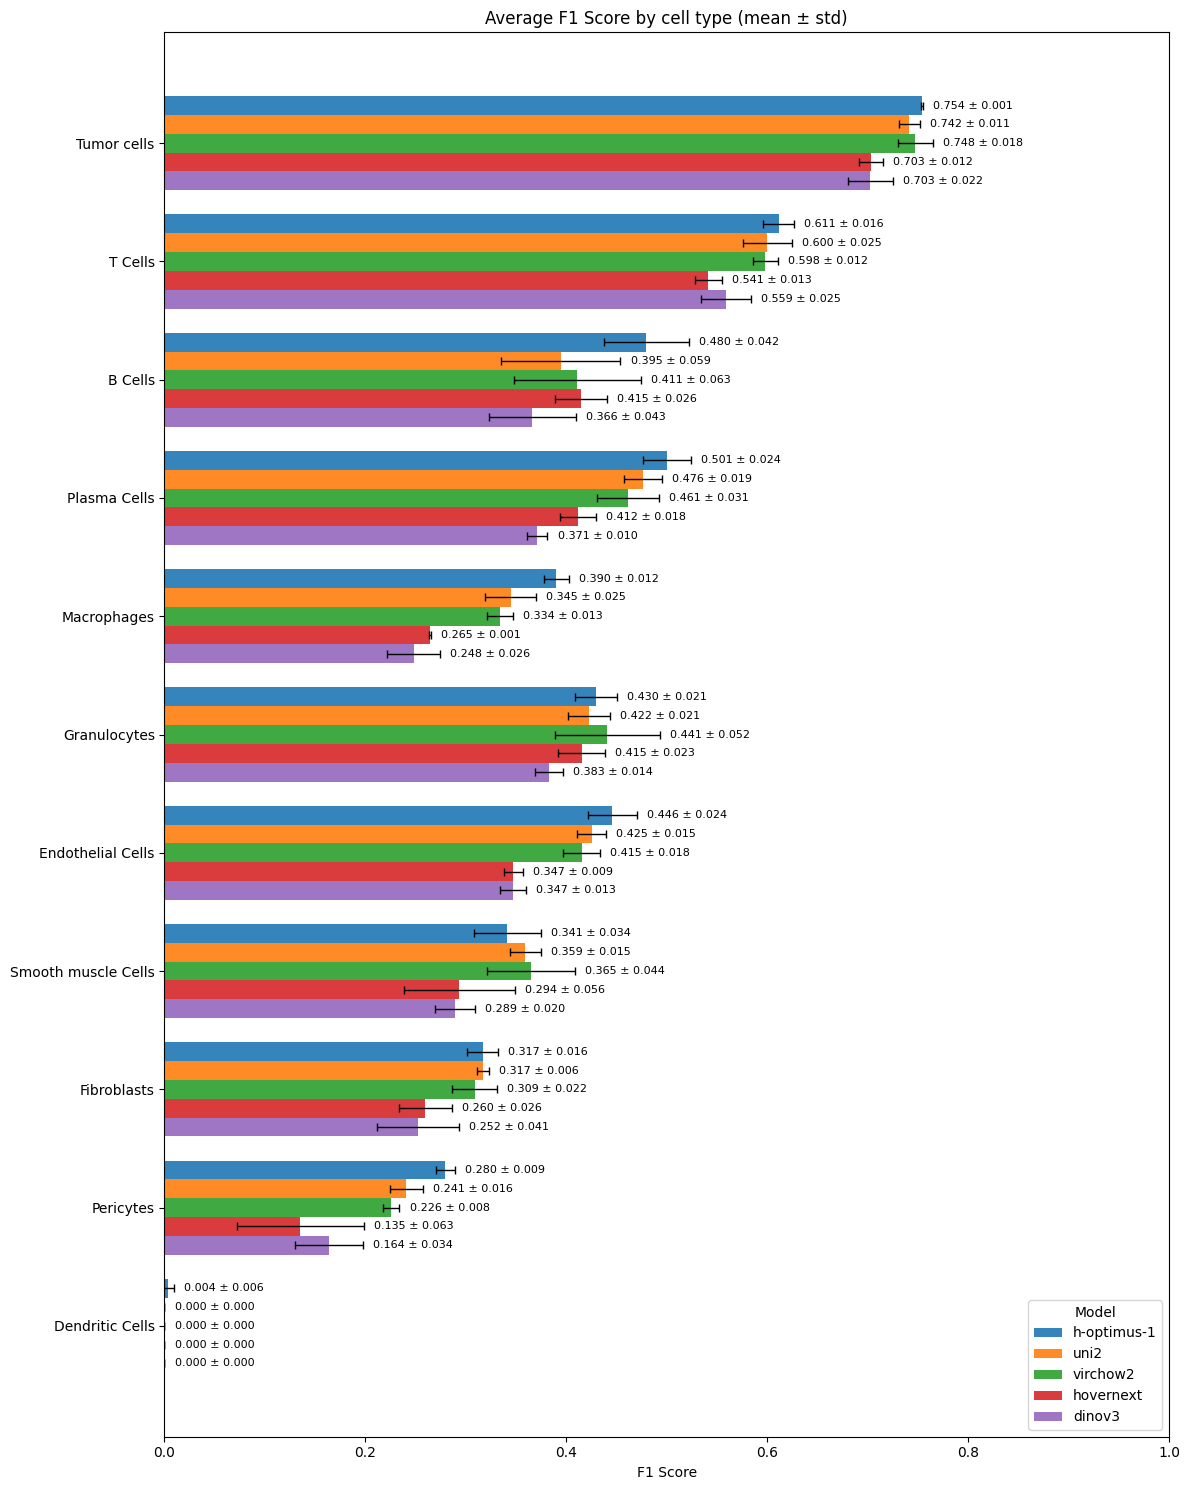

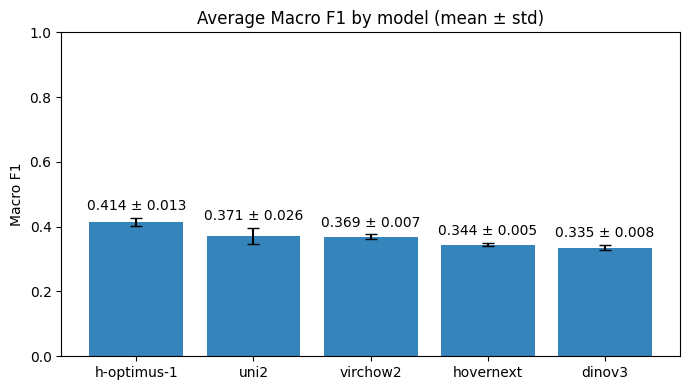

In [3]:
metric_name = "f1_score"  # change to "precision", "recall", or "accuracy" if needed

def normalize_column_name(name):
    return "".join(char for char in name.lower() if char.isalnum())

def load_per_class_scores(csv_path, metric):
    row = pd.read_csv(csv_path).iloc[0]
    scores = {}
    for column, value in row.items():
        if "/" not in column:
            continue
        cell_type, column_metric = column.rsplit("/", 1)
        if column_metric == metric:
            scores[cell_type] = value
    return pd.Series(scores, dtype=float)

def load_macro_f1(csv_path):
    row = pd.read_csv(csv_path).iloc[0]
    for column, value in row.items():
        normalized = normalize_column_name(column)
        if "macro" in normalized and "f1" in normalized:
            return float(value)
    raise KeyError(f"Could not find a macro F1 column in {csv_path}")

def collect_per_class_runs(csv_paths, metric):
    per_run_scores = [load_per_class_scores(path, metric) for path in csv_paths]
    if not per_run_scores:
        return pd.DataFrame()
    return pd.concat(per_run_scores, axis=1)

# Build run-level per-class scores for each model, then compute mean/std across versions.
per_model_runs = {
    model: collect_per_class_runs(paths, metric_name)
    for model, paths in model_results_files.items()
}

scores_mean = pd.concat(
    [runs.mean(axis=1, skipna=True).rename(model) for model, runs in per_model_runs.items()],
    axis=1,
    join="inner",
)
scores_std = pd.concat(
    [runs.std(axis=1, ddof=1, skipna=True).fillna(0.0).rename(model) for model, runs in per_model_runs.items()],
    axis=1,
    join="inner",
)

cell_order = [
    "Tumor cells",
    "T Cells",
    "B Cells",
    "Plasma Cells",
    "Macrophages",
    "Granulocytes",
    "Endothelial Cells",
    "Smooth muscle Cells",
    "Fibroblasts",
    "Pericytes",
    "Dendritic Cells",
]

ordered_cells = [cell for cell in cell_order if cell in scores_mean.index]
scores_mean = scores_mean.reindex(ordered_cells)
scores_std = scores_std.reindex(ordered_cells)

n_cell_types = len(scores_mean.index)
n_models = len(scores_mean.columns)
bar_height = 0.35
group_spacing = 0.45
group_positions = np.arange(n_cell_types) * (n_models * bar_height + group_spacing)

fig_height = max(15, 0.45 * n_cell_types)
fig, ax = plt.subplots(figsize=(12, fig_height))

for i, model in enumerate(scores_mean.columns):
    offset = (i - (n_models - 1) / 2) * bar_height
    x = scores_mean[model].values
    xerr = np.nan_to_num(scores_std[model].values, nan=0.0)
    y = group_positions + offset
    bars = ax.barh(
        y,
        x,
        xerr=xerr,
        height=bar_height,
        label=model,
        color=plt.get_cmap("tab10")(i),
        alpha=0.9,
        ecolor="black",
        capsize=3,
        error_kw={"elinewidth": 1},
    )

    for yi, xi, si in zip(y, x, xerr):
        label_x = min(0.99, xi + si + 0.01)
        ax.text(
            label_x,
            yi,
            f"{xi:.3f} ± {si:.3f}",
            va="center",
            ha="left",
            fontsize=8,
        )
        
ax.set_yticks(group_positions)
ax.set_yticklabels(scores_mean.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel(metric_name.replace("_", " ").title())
ax.set_title(f"Average {metric_name.replace('_', ' ').title()} by cell type (mean ± std)")
ax.grid(False)
ax.legend(title="Model", loc="lower right")
plt.tight_layout()
plt.show()

macro_f1_values = {
    model: np.array([load_macro_f1(path) for path in paths], dtype=float)
    for model, paths in model_results_files.items()
    if paths
}

macro_f1_mean = pd.Series(
    {model: values.mean() for model, values in macro_f1_values.items()},
    dtype=float,
).sort_values(ascending=False)
macro_f1_std = pd.Series(
    {model: values.std(ddof=1) if len(values) > 1 else 0.0 for model, values in macro_f1_values.items()},
    dtype=float,
).reindex(macro_f1_mean.index).fillna(0.0)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    macro_f1_mean.index,
    macro_f1_mean.values,
    yerr=macro_f1_std.values,
    alpha=0.9,
    ecolor="black",
    capsize=4,
)

ax.set_ylim(0, 1)
ax.set_ylabel("Macro F1")
ax.set_title("Average Macro F1 by model (mean ± std)")
ax.grid(False)

for bar, std in zip(bars, macro_f1_std.values):
    height = bar.get_height()
    y_pos = min(0.995, height + std + 0.015)
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        y_pos,
        f"{height:.3f} ± {std:.3f}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

In [4]:
model_prediction_files = {
    "h-optimus-1": [
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_h-optimus-1_2010_1056_pathocell2_3726201/train/test_results/predictions.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_h-optimus-1_2110_2323_pathocell2_3752807/train/test_results/predictions.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_h-optimus-1_2110_2323_pathocell2_3752808/train/test_results/predictions.csv",
    ],
    "uni2": [
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_uni2_1610_1101_pathocell2_3658092/train/test_results/predictions.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_uni2_1710_1327_pathocell2_3679630/train/test_results/predictions.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_uni2_2110_1649_pathocell2_3749452/train/test_results/predictions.csv",
    ],
    "virchow2": [
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_virchow2_1910_1729_pathocell2_3720066/train/test_results/predictions.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_virchow2_2010_1051_pathocell2_3726138/train/test_results/predictions.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_virchow2_2110_1649_pathocell2_3749456/train/test_results/predictions.csv",
    ],
    "hovernext": [
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/hovernext_lizard_clweight_convnextv2_large.fcmae_ft_in22k_in1k_1610_1346_pathocell2_3663596/train/test_results/predictions.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/hovernext_lizard_clweight_convnextv2_large.fcmae_ft_in22k_in1k_2110_1649_pathocell2_3749396/train/test_results/predictions.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/hovernext_lizard_clweight_convnextv2_large.fcmae_ft_in22k_in1k_2110_1649_pathocell2_3749454/train/test_results/predictions.csv",
    ],
    "dinov3": [
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_dinov3_2010_1211_pathocell2_3726333/train/test_results/predictions.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_dinov3_2010_1201_pathocell2_3726312/train/test_results/predictions.csv",
        "/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_dinov3_2110_1647_pathocell2_3749379/train/test_results/predictions.csv",
    ]
}

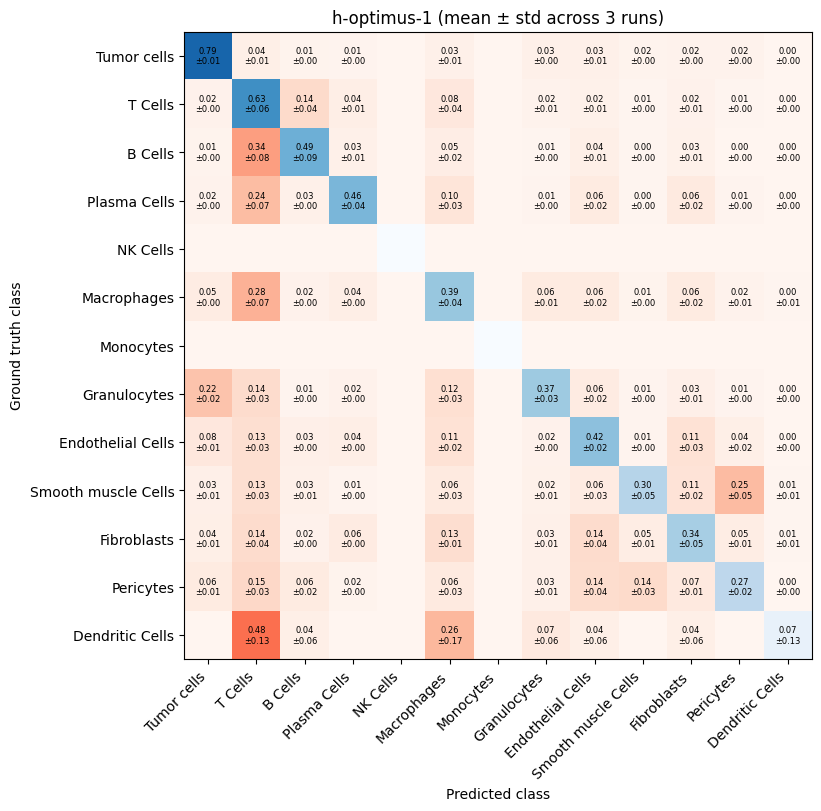

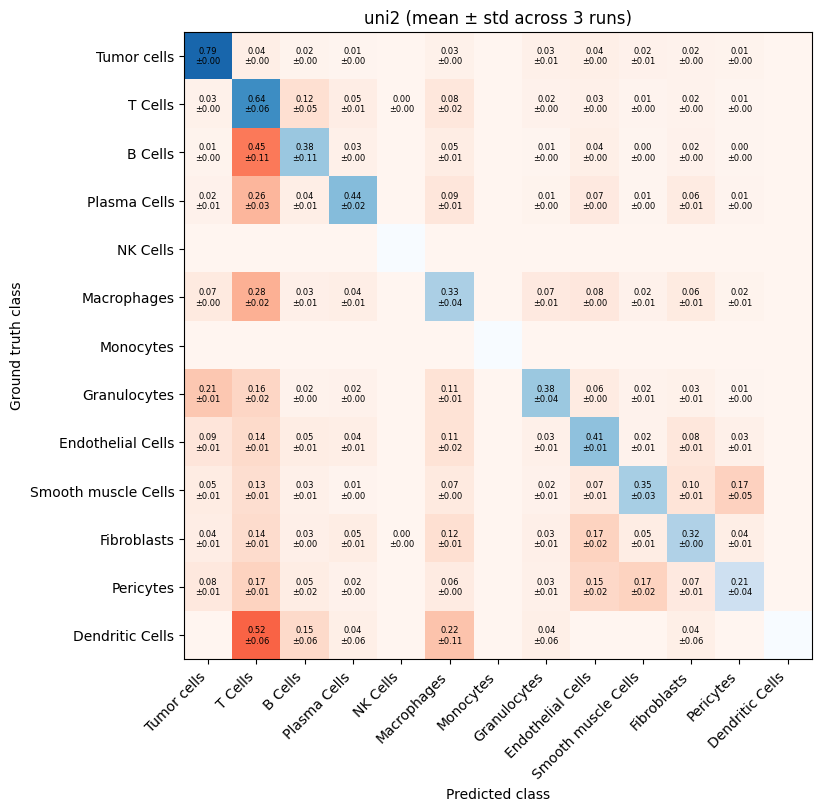

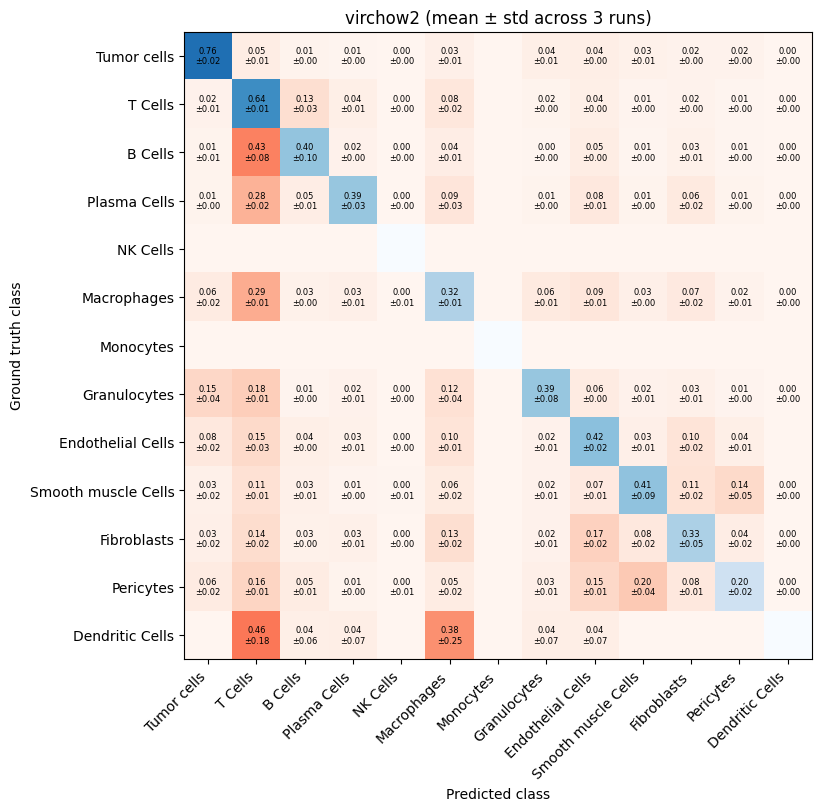

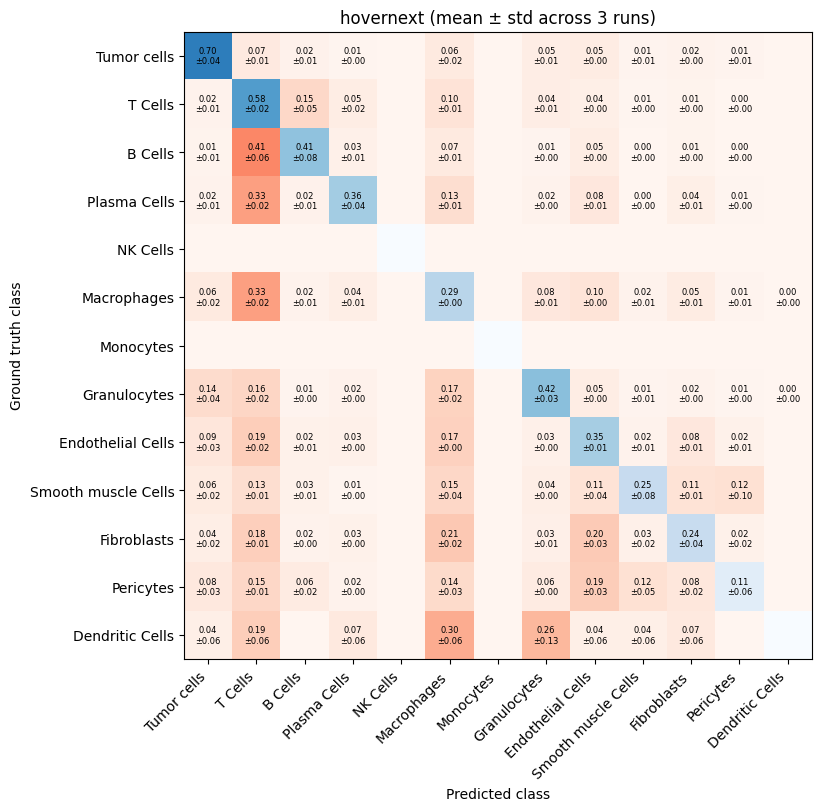

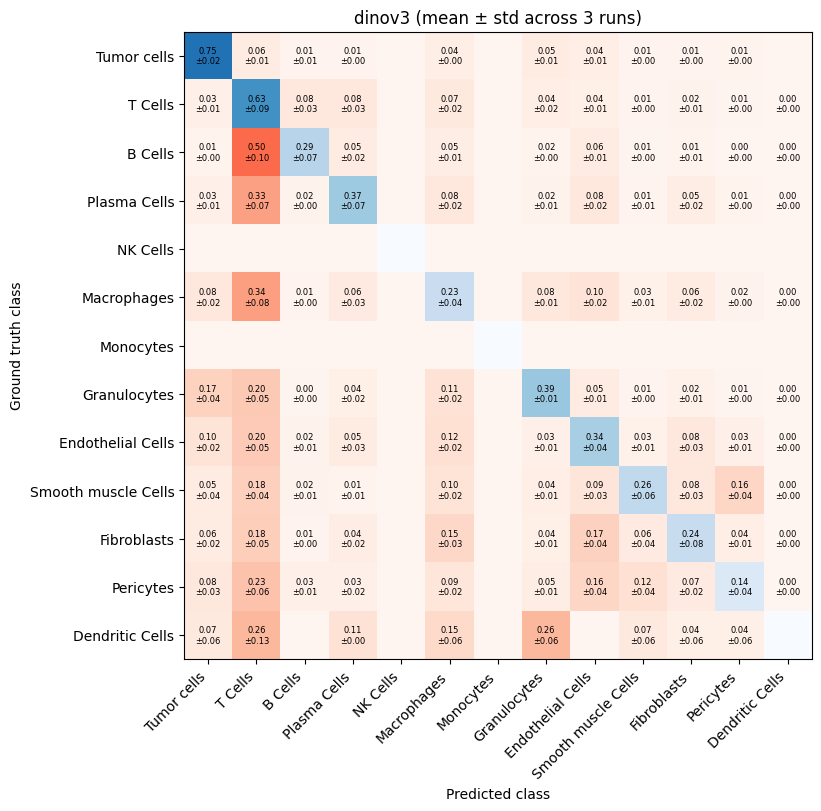

In [5]:
class_names = [
    "Tumor cells",
    "T Cells",
    "B Cells",
    "Plasma Cells",
    "NK Cells",
    "Macrophages",
    "Monocytes", # ?
    "Granulocytes",
    "Endothelial Cells", # --> Vascvular?
    "Smooth muscle Cells",
    "Fibroblasts", # --> Stroma?
    "Pericytes", # ?
    "Dendritic Cells",
]

label_to_name = {idx + 1: name for idx, name in enumerate(class_names)}
model_files = model_prediction_files

def build_confusion_matrix(df):
    df = df[df["groundtruth"].isin(label_to_name)]
    df = df[df["pred_class_name"].isin(class_names)]

    y_true = df["groundtruth"].map(label_to_name)
    y_pred = df["pred_class_name"]

    cm = pd.crosstab(
        pd.Categorical(y_true, categories=class_names, ordered=True),
        pd.Categorical(y_pred, categories=class_names, ordered=True),
        dropna=False,
    ).reindex(index=class_names, columns=class_names, fill_value=0)

    row_totals = cm.sum(axis=1).replace(0, np.nan)
    return cm.div(row_totals, axis=0).fillna(0)

def build_confusion_stats(csv_paths):
    if not csv_paths:
        raise ValueError("At least one prediction CSV is required per model.")

    run_matrices = []
    for path in csv_paths:
        df = pd.read_csv(path)
        cm_pct = build_confusion_matrix(df)
        run_matrices.append(cm_pct.values)

    stack = np.stack(run_matrices, axis=0)
    cm_mean = stack.mean(axis=0)
    if stack.shape[0] > 1:
        cm_std = stack.std(axis=0, ddof=1)
    else:
        cm_std = np.zeros_like(cm_mean)

    return cm_mean, cm_std, stack.shape[0]

for model_name, csv_paths in model_files.items():
    matrix_mean, matrix_std, n_runs = build_confusion_stats(csv_paths)
    diagonal_mask = np.eye(matrix_mean.shape[0], dtype=bool)
    off_diagonal_mask = ~diagonal_mask

    fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
    ax.set_title(f"{model_name} (mean ± std across {n_runs} runs)")
    ax.set_xticks(np.arange(len(class_names)))
    ax.set_yticks(np.arange(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Ground truth class")

    blue_cmap = plt.cm.Blues.copy()
    red_cmap = plt.cm.Reds.copy()
    blue_cmap.set_bad(alpha=0)
    red_cmap.set_bad(alpha=0)

    off_diagonal_data = np.ma.array(matrix_mean, mask=~off_diagonal_mask)
    diagonal_data = np.ma.array(matrix_mean, mask=~diagonal_mask)

    ax.imshow(off_diagonal_data, cmap=red_cmap, vmin=0, vmax=1)
    ax.imshow(diagonal_data, cmap=blue_cmap, vmin=0, vmax=1)

    for i in range(matrix_mean.shape[0]):
        for j in range(matrix_mean.shape[1]):
            mean_value = matrix_mean[i, j]
            std_value = matrix_std[i, j]
            if mean_value > 0 or std_value > 0:
                ax.text(
                    j,
                    i,
                    f"{mean_value:.2f}\n±{std_value:.2f}",
                    ha="center",
                    va="center",
                    color="black",
                    fontsize=6,
                )

    plt.show()